# Data Overview

A descriptive look at the creativity ratings before the model-based analysis:
how much data there is, how it is distributed across products and raters, how
well connected the rater–product design is, and the raters' response styles.

This notebook reads the preprocessed data produced by
`00_data_loading_preprocessing.ipynb` (`data/processed/ratings_long_clean.csv`)
and applies the same rater exclusion as the models (raters with fewer than 15
ratings, `results/data/excluded_raters.csv`).
The scoring and reliability analysis is the JRT graded response model in
`../R/` (see `../AUDIT.md`); the checked design tables used by the models
(category use per rater, rater overlap, connectivity) are written by
`../R/01_data_design.R`.

## 1. Load the preprocessed data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from IPython.display import Markdown

def fmt_cell(v, digits=3):
    # Display formatting only: whole numbers without decimals.
    if isinstance(v, (int, np.integer)) or (isinstance(v, float) and v.is_integer()):
        return f"{int(v)}"
    return f"{v:.{digits}f}" if isinstance(v, float) else str(v)

def show_table(df_table, digits=3):
    # Markdown table without the index column, for embedding in the manuscript.
    # Columns with any non-integer value show all values with decimals (3 -> 3.000);
    # the quantity/value table keeps whole numbers without decimals.
    out = df_table.copy().astype(object)
    for col in out.columns:
        num = pd.to_numeric(df_table[col], errors="coerce")
        dec = col != "value" and num.notna().any() and not (num.dropna() % 1 == 0).all()
        out[col] = [f"{float(v):,.{digits}f}" if dec and pd.notna(n) else fmt_cell(v, digits)
                    for v, n in zip(df_table[col], num)]
    return Markdown(out.to_markdown(index=False, disable_numparse=True))

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

PROJECT_ROOT = Path("..").resolve()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(DATA_PROCESSED / "ratings_long_clean.csv")
df["action_id"] = df["action_id"].astype(str)
df["rater_id"] = df["rater_id"].astype(str)

# Same rater exclusion as the models: raters with fewer than 15 ratings are removed
# in ../R/01_data_design.R and listed in results/data/excluded_raters.csv.
excluded = pd.read_csv(PROJECT_ROOT / "results" / "data" / "excluded_raters.csv")
counts = df["rater_id"].value_counts()
assert set(counts[counts < 15].index) == set(excluded["rater_id"]), (
    "excluded_raters.csv is out of date: run R/01_data_design.R before this notebook")
n_before = len(df)
df = df[~df["rater_id"].isin(excluded["rater_id"])].copy()

print(f"Loaded {n_before} ratings; excluded {n_before - len(df)} ratings from "
      f"{len(excluded)} raters with fewer than 15 ratings "
      f"({', '.join(excluded['rater_id'])}); {len(df)} ratings remain.")
df.head()

Loaded 9077 ratings; excluded 31 ratings from 4 raters with fewer than 15 ratings (R20, R21, R22, R28); 9046 ratings remain.


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,R27,77f4cd20-ce3c-4e8a-b6a7-6dcfcde3e5f3,1.0,3.0,1.0,2026-10-23 14:26:38.757,1,1,47
1,R25,804fe050-67ca-4bbe-a04b-f5cad5beed34,5.0,4.0,3.0,2026-10-23 11:27:24.382,5,5,103
2,R25,7ce1a402-416c-4ecd-bfc3-eea5fad67744,4.0,5.0,4.0,2026-10-23 11:26:44.684,4,4,102
3,R25,fd3afe07-ed42-46a6-a43f-fa619dc911a4,2.0,3.0,1.0,2026-10-23 11:26:13.078,2,2,101
4,R25,012abd99-d8ad-4044-976f-42af0d62852c,5.0,5.0,5.0,2026-10-23 11:25:38.219,5,5,100


## 2. How much data do we have

Total number of ratings, and how many distinct products and raters they
cover.

In [2]:
n_ratings = len(df)
n_actions = df["action_id"].nunique()
n_raters = df["rater_id"].nunique()

print(f"Total ratings:   {n_ratings}")
print(f"Distinct products: {n_actions}")
print(f"Distinct raters:  {n_raters}")
print(f"Average ratings per product: {n_ratings / n_actions:.2f}")
print(f"Average ratings per rater:  {n_ratings / n_raters:.1f}")

Total ratings:   9046
Distinct products: 3669
Distinct raters:  24
Average ratings per product: 2.47
Average ratings per rater:  376.9


## 3. Distribution of the number of ratings

Some products have only one rating and contribute no within-product
agreement information; some raters have rated far more products than
others. Both matter for how much we can trust the eventual reliability
estimates.

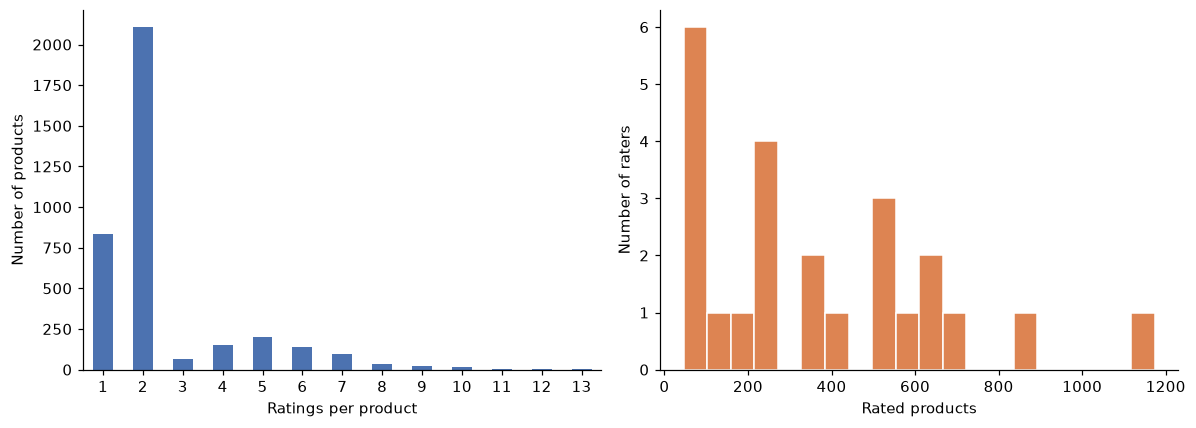

Ratings per product:
n_ratings
1      832
2     2107
3       68
4      153
5      198
6      137
7       95
8       36
9       22
10      14
11       4
12       2
13       1
Name: count, dtype: int64

Cumulative ratings per product:
1 or more ratings     3669
2 or more ratings     2837
3 or more ratings      730
4 or more ratings      662
5 or more ratings      509
6 or more ratings      311
7 or more ratings      174
8 or more ratings       79
9 or more ratings       43
10 or more ratings      21
11 or more ratings       7
12 or more ratings       3
13 or more ratings       1
Name: count, dtype: int64

Ratings per rater:
rater_id
R26      46
R27      47
R19      50
R17      52
R18      55
R15      73
R25     138
R24     190
R13     254
R14     259
R12     264
R16     268
R11     369
R10     383
R09     400
R06     520
R08     522
R07     547
R23     589
R04     620
R05     633
R03     720
R02     873
R01    1174
Name: n_actions_rated, dtype: int64


In [3]:
ratings_per_action = df.groupby("action_id").size().rename("n_ratings")
ratings_per_rater = df.groupby("rater_id").size().rename("n_actions_rated")
ratings_cum = ratings_per_action.value_counts().sort_index(ascending=False).cumsum()
ratings_cum = ratings_cum.sort_index(ascending=True)
ratings_cum.index = [f"{x} or more ratings" for x in ratings_cum.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ratings_per_action.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_xlabel("Ratings per product")
axes[0].set_ylabel("Number of products")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

axes[1].hist(ratings_per_rater.values, bins=min(20, n_raters), color="#DD8452", edgecolor="white")
axes[1].set_xlabel("Rated products")
axes[1].set_ylabel("Number of raters")
fig.tight_layout()
plt.show()

print("Ratings per product:")
print(ratings_per_action.value_counts().sort_index())
print("\nCumulative ratings per product:")
print(ratings_cum)

print("\nRatings per rater:")
print(ratings_per_rater.sort_values())

In [4]:
RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_TABLES.mkdir(parents=True, exist_ok=True)

n_one = int((ratings_per_action == 1).sum())
n_two = int((ratings_per_action == 2).sum())
n_three_plus = int((ratings_per_action >= 3).sum())
k_mean = float(ratings_per_action.mean())
k_harmonic_all = float(len(ratings_per_action) / (1.0 / ratings_per_action).sum())
sample_ratings_per_action = pd.DataFrame({
    "quantity": ["n_ratings", "n_products", "n_raters",
                 "n_products_1_rating", "n_products_2_ratings", "n_products_3plus_ratings",
                 "share_products_1_rating", "share_products_2_ratings", "share_products_3plus_ratings",
                 "max_ratings_per_product", "mean_ratings_per_product", "harmonic_mean_ratings_per_product",
                 "median_ratings_per_rater", "min_ratings_per_rater", "max_ratings_per_rater"],
    "value": [n_ratings, n_actions, n_raters,
              n_one, n_two, n_three_plus,
              n_one / n_actions, n_two / n_actions, n_three_plus / n_actions,
              int(ratings_per_action.max()), k_mean, k_harmonic_all,
              float(ratings_per_rater.median()), int(ratings_per_rater.min()), int(ratings_per_rater.max())],
})
sample_ratings_per_action.to_csv(RESULTS_TABLES / "sample_ratings_per_action.csv", index=False)

In [5]:
#| label: tbl-overview-ratings-per-action
#| tbl-cap: "Number of products by number of ratings received, with the mean and harmonic mean number of ratings per product."
show_table(sample_ratings_per_action)

| quantity                          | value   |
|:----------------------------------|:--------|
| n_ratings                         | 9046    |
| n_products                        | 3669    |
| n_raters                          | 24      |
| n_products_1_rating               | 832     |
| n_products_2_ratings              | 2107    |
| n_products_3plus_ratings          | 730     |
| share_products_1_rating           | 0.227   |
| share_products_2_ratings          | 0.574   |
| share_products_3plus_ratings      | 0.199   |
| max_ratings_per_product           | 13      |
| mean_ratings_per_product          | 2.466   |
| harmonic_mean_ratings_per_product | 1.806   |
| median_ratings_per_rater          | 318.500 |
| min_ratings_per_rater             | 46      |
| max_ratings_per_rater             | 1174    |

## 4. Connectivity of the rater–product design

Rater severity/leniency can only be told apart from true differences
between products if raters are linked, directly or indirectly, through
shared products. We build the rater–product bipartite graph and check how
connected it currently is, and how much overlap each pair of raters has.

In [6]:
B = nx.Graph()
B.add_nodes_from(df["action_id"].unique(), bipartite="action")
B.add_nodes_from(("R::" + df["rater_id"]).unique(), bipartite="rater")
B.add_edges_from(zip(df["action_id"], "R::" + df["rater_id"]))

components = sorted(nx.connected_components(B), key=len, reverse=True)
comp_summary = []
for i, comp in enumerate(components):
    action_nodes = [n for n in comp if not str(n).startswith("R::")]
    rater_nodes = [str(n)[3:] for n in comp if str(n).startswith("R::")]
    comp_summary.append({
        "component_id": i, "n_products": len(action_nodes),
        "n_raters": len(rater_nodes), "raters": ", ".join(sorted(rater_nodes)),
    })
comp_summary_df = pd.DataFrame(comp_summary)
print(f"Number of connected components: {len(components)}")
comp_summary_df

Number of connected components: 1


,component_id,n_products,n_raters,raters
0,0,3669,24,"R01, R02, R03, R04, R05, R06, R07, R08, R09, R..."


In [7]:
rater_ids_sorted = sorted(df["rater_id"].unique())
n = len(rater_ids_sorted)
rater_idx = {r: i for i, r in enumerate(rater_ids_sorted)}

overlap = np.zeros((n, n), dtype=int)
for raters_for_action in df.groupby("action_id")["rater_id"].apply(list):
    idxs = sorted(set(rater_idx[r] for r in raters_for_action))
    for a in range(len(idxs)):
        for b in range(a + 1, len(idxs)):
            overlap[idxs[a], idxs[b]] += 1
            overlap[idxs[b], idxs[a]] += 1

overlap_df = pd.DataFrame(overlap, index=rater_ids_sorted, columns=rater_ids_sorted)

# For each rater: overlap with their single best-connected partner.
best_partner_overlap = pd.Series(
    {r: overlap_df.loc[r].drop(r).max() for r in rater_ids_sorted},
    name="best_partner_overlap",
).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(overlap, cmap="viridis")
ax.set_xticks(range(n)); ax.set_xticklabels(rater_ids_sorted, rotation=90, fontsize=7)
ax.set_yticks(range(n)); ax.set_yticklabels(rater_ids_sorted, fontsize=7)
ax.set_xlabel("Rater"); ax.set_ylabel("Rater")
fig.colorbar(im, ax=ax, shrink=0.8, label="Jointly rated products")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "results" / "figures" / "fig_overview_rater_overlap.png", bbox_inches="tight", dpi=200)
fig.savefig(PROJECT_ROOT / "results" / "figures" / "fig_overview_rater_overlap.svg", bbox_inches="tight")
plt.close(fig)

print("Best-connected-partner overlap per rater (lower = more isolated):")
print(best_partner_overlap)

Best-connected-partner overlap per rater (lower = more isolated):
R26     19
R27     42
R17     44
R19     46
R18     50
R15     64
R14    108
R25    125
R12    145
R09    147
R13    154
R10    157
R24    167
R05    190
R08    191
R16    227
R06    240
R02    257
R04    257
R01    329
R03    329
R11    357
R07    371
R23    371
Name: best_partner_overlap, dtype: int64


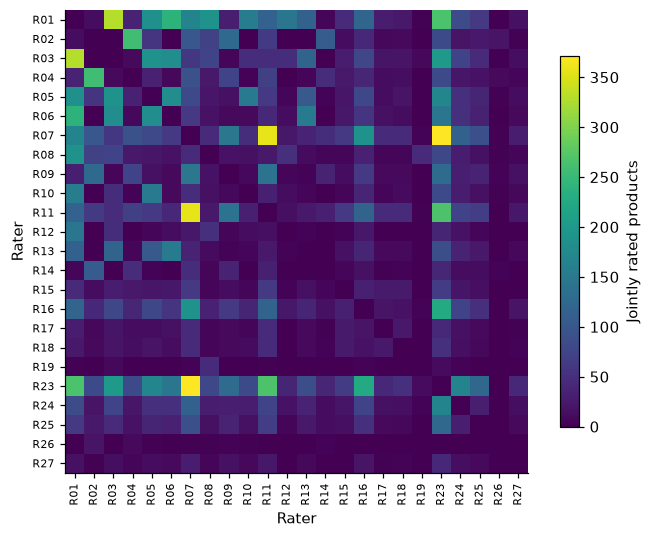

In [8]:
#| label: fig-overview-rater-overlap
#| fig-cap: "Number of jointly rated products for each pair of raters."
fig

## 5. Design diagnostics

Properties of the rating design and of the raters' response styles, which do
not depend on any scoring approach.

In [9]:
from scipy import stats as sps

RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
for d in [RESULTS_TABLES, RESULTS_FIGURES]:
    d.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name, caption=None):
    fig.savefig(RESULTS_FIGURES / f"{name}.png", bbox_inches="tight", dpi=200)
    fig.savefig(RESULTS_FIGURES / f"{name}.svg", bbox_inches="tight")
    if caption:
        (RESULTS_FIGURES / f"{name}_caption.txt").write_text(caption)

def save_table(df_table, name, index=False):
    df_table.to_csv(RESULTS_TABLES / f"{name}.csv", index=index)

### 5.1 Distribution of all ratings

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
df["rating_numeric"].value_counts().reindex(range(1, 8), fill_value=0).plot(kind="bar", ax=ax, color="#55A868")
ax.set_xlabel("Creativity rating (1 = not creative, 7 = very creative)")
ax.set_ylabel("Frequency")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
fig.tight_layout()
save_fig(fig, "fig_overview_rating_distribution",
         "Frequency of the seven rating categories across all ratings.")
plt.close(fig)

category_counts = df["rating_numeric"].value_counts().reindex(range(1, 8), fill_value=0)
category_table = pd.DataFrame({"category": range(1, 8), "n": category_counts.values,
                               "share": category_counts.values / len(df)})
save_table(category_table, "overview_category_frequencies")
print(category_table.to_string(index=False))

 category    n    share
        1 2179 0.240880
        2 2355 0.260336
        3 1777 0.196440
        4 1282 0.141720
        5  909 0.100486
        6  416 0.045987
        7  128 0.014150


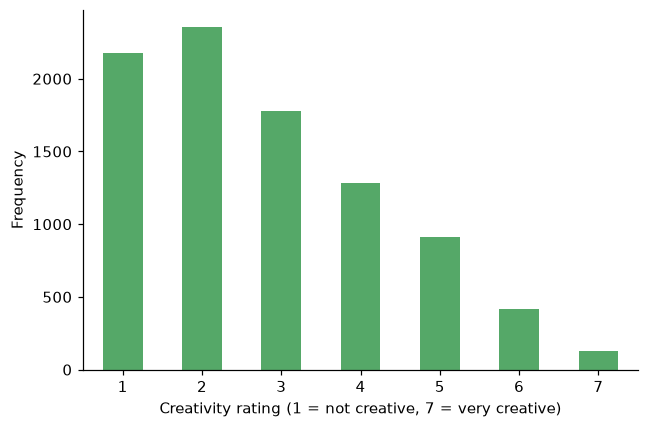

In [11]:
#| label: fig-overview-rating-distribution
#| fig-cap: "Frequency of the seven rating categories across all ratings."
fig

### 5.2 Rater response styles

Per rater: mean, median, SD, IQR, floor/ceiling rates, number of categories
used, entropy of the category distribution, and the shares of middle (3–5)
vs. extreme (1, 7) categories. These descriptives anticipate what the models
estimate formally: severity (the mean), scale width/discrimination (SD,
entropy), and central or extreme tendency.

In [12]:
def rater_summary(g):
    vals = g["rating_numeric"]
    n_cat = vals.nunique()
    p_extreme = vals.isin([1, 7]).mean()
    p_central = vals.isin([3, 4, 5]).mean()
    probs = vals.value_counts(normalize=True)
    entropy = -(probs * np.log(probs.clip(lower=1e-12))).sum()
    return pd.Series({
        "n_ratings": len(vals),
        "n_products": g["action_id"].nunique(),
        "mean": vals.mean(),
        "median": vals.median(),
        "sd": vals.std(),
        "iqr": vals.quantile(0.75) - vals.quantile(0.25),
        "n_categories_used": n_cat,
        "entropy": entropy,
        "floor_rate": (vals == 1).mean(),
        "ceiling_rate": (vals == 7).mean(),
        "extreme_category_rate": p_extreme,
        "central_category_rate": p_central,
    })

rater_desc = df.groupby("rater_id").apply(rater_summary, include_groups=False).reset_index()
rater_desc = rater_desc.sort_values("mean").reset_index(drop=True)
save_table(rater_desc, "rater_descriptive_statistics")
rater_desc.round(3)

,rater_id,n_ratings,n_products,mean,median,sd,iqr,n_categories_used,entropy,floor_rate,ceiling_rate,extreme_category_rate,central_category_rate
0,R06,520.0,520.0,1.760,1.0,1.111,1.0,6.0,1.191,0.579,0.000,0.579,0.192
1,R27,47.0,47.0,2.064,2.0,1.241,2.0,5.0,1.337,0.447,0.000,0.447,0.277
2,R17,52.0,52.0,2.077,2.0,1.296,2.0,5.0,1.367,0.481,0.000,0.481,0.327
3,R01,1174.0,1174.0,2.164,2.0,1.022,2.0,6.0,1.358,0.287,0.000,0.287,0.315
4,R14,259.0,259.0,2.220,2.0,1.359,2.0,7.0,1.496,0.405,0.008,0.413,0.313
5,R11,369.0,369.0,2.333,2.0,1.397,2.0,7.0,1.532,0.344,0.003,0.347,0.309
6,R07,547.0,547.0,2.404,2.0,1.406,2.0,7.0,1.580,0.335,0.004,0.338,0.353
7,R05,633.0,633.0,2.716,2.0,1.554,3.0,7.0,1.700,0.251,0.019,0.270,0.382
8,R03,720.0,720.0,2.750,3.0,1.402,2.0,6.0,1.643,0.224,0.000,0.224,0.493
9,R04,620.0,620.0,2.821,2.0,1.628,3.0,7.0,1.715,0.265,0.008,0.273,0.405


In [13]:
#| label: tbl-overview-rater-response-styles
#| tbl-cap: "Descriptive response styles per rater: number of ratings, mean, median, standard deviation and interquartile range of the ratings, number of categories used (of 7), entropy of the category distribution, and the shares of ratings in the lowest category (1), the highest category (7), the extreme categories (1 or 7) and the middle categories (3 to 5)."
show_table(rater_desc.drop(columns=["n_products"]).rename(columns={
    "rater_id": "Rater", "n_ratings": "Ratings by rater", "mean": "Mean", "median": "Median", "sd": "SD",
    "iqr": "IQR", "n_categories_used": "Categories used", "entropy": "Entropy",
    "floor_rate": "Share lowest (1)", "ceiling_rate": "Share highest (7)",
    "extreme_category_rate": "Share extreme (1, 7)", "central_category_rate": "Share middle (3-5)"}))

| Rater   | Ratings by rater   | Mean   | Median   | SD    | IQR   | Categories used   | Entropy   | Share lowest (1)   | Share highest (7)   | Share extreme (1, 7)   | Share middle (3-5)   |
|:--------|:-------------------|:-------|:---------|:------|:------|:------------------|:----------|:-------------------|:--------------------|:-----------------------|:---------------------|
| R06     | 520                | 1.760  | 1        | 1.111 | 1     | 6                 | 1.191     | 0.579              | 0.000               | 0.579                  | 0.192                |
| R27     | 47                 | 2.064  | 2        | 1.241 | 2     | 5                 | 1.337     | 0.447              | 0.000               | 0.447                  | 0.277                |
| R17     | 52                 | 2.077  | 2        | 1.296 | 2     | 5                 | 1.367     | 0.481              | 0.000               | 0.481                  | 0.327                |
| R01     | 1174               | 2.164  | 2        | 1.022 | 2     | 6                 | 1.358     | 0.287              | 0.000               | 0.287                  | 0.315                |
| R14     | 259                | 2.220  | 2        | 1.359 | 2     | 7                 | 1.496     | 0.405              | 0.008               | 0.413                  | 0.313                |
| R11     | 369                | 2.333  | 2        | 1.397 | 2     | 7                 | 1.532     | 0.344              | 0.003               | 0.347                  | 0.309                |
| R07     | 547                | 2.404  | 2        | 1.406 | 2     | 7                 | 1.580     | 0.335              | 0.004               | 0.338                  | 0.353                |
| R05     | 633                | 2.716  | 2        | 1.554 | 3     | 7                 | 1.700     | 0.251              | 0.019               | 0.270                  | 0.382                |
| R03     | 720                | 2.750  | 3        | 1.402 | 2     | 6                 | 1.643     | 0.224              | 0.000               | 0.224                  | 0.493                |
| R04     | 620                | 2.821  | 2        | 1.628 | 3     | 7                 | 1.715     | 0.265              | 0.008               | 0.273                  | 0.405                |
| R10     | 383                | 2.997  | 3        | 1.311 | 2     | 7                 | 1.564     | 0.065              | 0.005               | 0.070                  | 0.488                |
| R08     | 522                | 3.000  | 3        | 1.545 | 2     | 7                 | 1.761     | 0.193              | 0.013               | 0.207                  | 0.492                |
| R26     | 46                 | 3.000  | 3        | 1.265 | 2     | 6                 | 1.605     | 0.109              | 0.000               | 0.109                  | 0.587                |
| R25     | 138                | 3.029  | 3        | 1.249 | 2     | 6                 | 1.602     | 0.130              | 0.000               | 0.130                  | 0.638                |
| R02     | 873                | 3.032  | 3        | 1.841 | 3     | 7                 | 1.822     | 0.276              | 0.052               | 0.328                  | 0.391                |
| R16     | 268                | 3.086  | 3        | 1.323 | 2     | 7                 | 1.661     | 0.108              | 0.011               | 0.119                  | 0.604                |
| R12     | 264                | 3.360  | 3        | 1.152 | 1     | 7                 | 1.547     | 0.042              | 0.004               | 0.045                  | 0.735                |
| R15     | 73                 | 3.466  | 3        | 1.700 | 3     | 7                 | 1.793     | 0.096              | 0.027               | 0.123                  | 0.452                |
| R23     | 589                | 3.469  | 3        | 1.531 | 3     | 7                 | 1.799     | 0.110              | 0.029               | 0.139                  | 0.625                |
| R09     | 400                | 3.643  | 4        | 1.819 | 3     | 7                 | 1.903     | 0.158              | 0.055               | 0.212                  | 0.495                |
| R19     | 50                 | 3.680  | 4        | 1.953 | 3     | 7                 | 1.902     | 0.200              | 0.080               | 0.280                  | 0.480                |
| R13     | 254                | 3.681  | 4        | 1.116 | 1     | 7                 | 1.520     | 0.016              | 0.004               | 0.020                  | 0.799                |
| R24     | 190                | 3.747  | 4        | 1.593 | 3     | 7                 | 1.790     | 0.084              | 0.011               | 0.095                  | 0.568                |
| R18     | 55                 | 3.836  | 4        | 1.259 | 2     | 6                 | 1.584     | 0.018              | 0.000               | 0.018                  | 0.764                |

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(rater_desc["mean"], bins=20, color="#4C72B0")
axes[0, 0].set_xlabel("Rater mean rating"); axes[0, 0].set_ylabel("Number of raters")
axes[0, 1].hist(rater_desc["sd"], bins=20, color="#DD8452")
axes[0, 1].set_xlabel("Rater SD of ratings"); axes[0, 1].set_ylabel("Number of raters")
axes[1, 0].hist(rater_desc["n_categories_used"], bins=np.arange(1, 9) - 0.5, color="#55A868", edgecolor="white")
axes[1, 0].set_xticks(range(1, 8))
axes[1, 0].set_xlabel("Number of categories used (of 7)"); axes[1, 0].set_ylabel("Number of raters")
axes[1, 1].scatter(rater_desc["extreme_category_rate"], rater_desc["central_category_rate"],
                    s=20 + rater_desc["n_ratings"] / 5, alpha=0.7, color="#C44E52")
axes[1, 1].set_xlabel("Share of extreme categories (1, 7)")
axes[1, 1].set_ylabel("Share of middle categories (3-5)")
from matplotlib.ticker import MaxNLocator
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
for ax, letter in zip(axes.flat, "ABCD"):
    ax.text(-0.12, 1.04, letter, transform=ax.transAxes, fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_overview_rater_response_styles",
         "Descriptive rater response styles: (A) rater means, (B) rater standard deviations, "
         "(C) number of rating categories used, (D) share of extreme (1, 7) versus middle (3-5) "
         "categories; point size is proportional to the number of ratings.")
plt.close(fig)

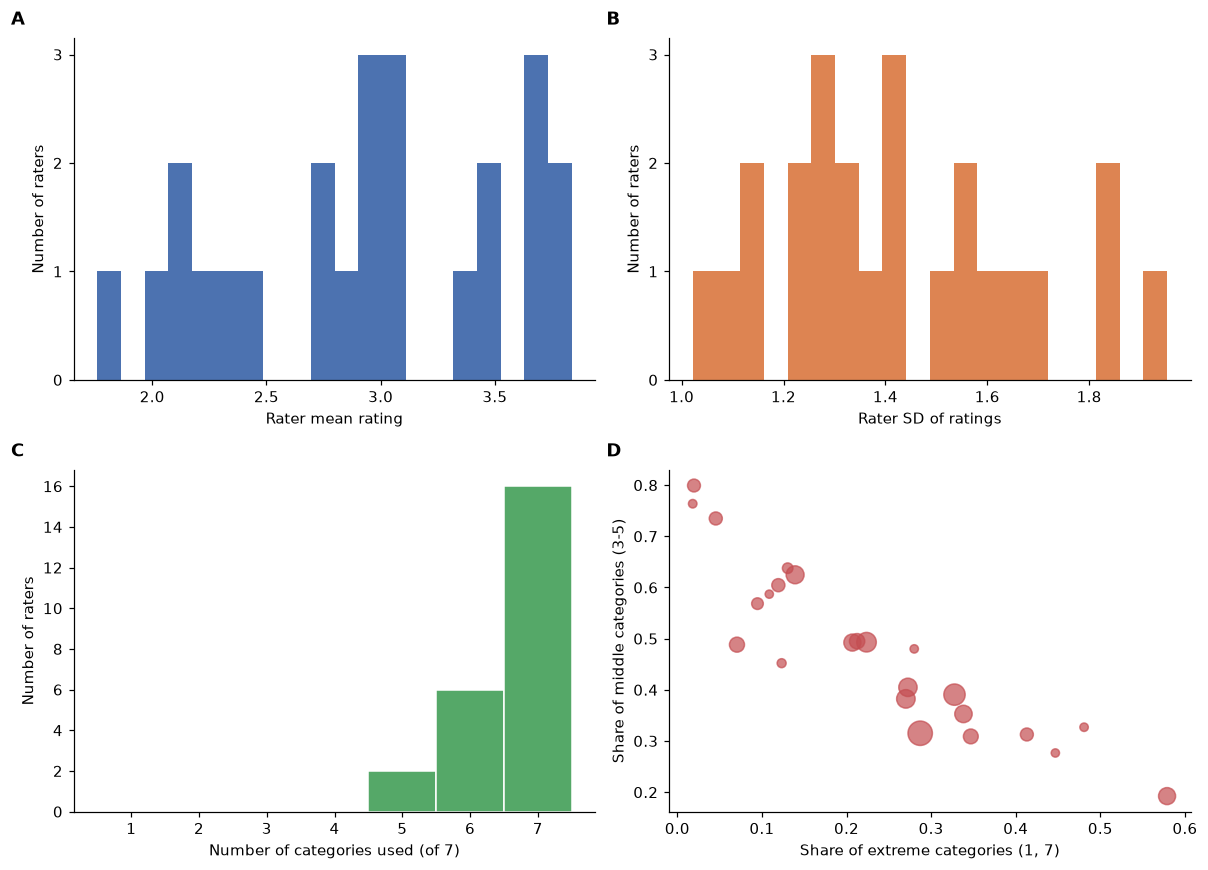

In [15]:
#| label: fig-overview-rater-response-styles
#| fig-cap: "Descriptive rater response styles: (A) rater means, (B) rater standard deviations, (C) number of rating categories used, (D) share of extreme (1, 7) versus middle (3-5) categories; point size is proportional to the number of ratings."
fig

### 5.3 Degree distributions and component summary

Degrees in the bipartite rater–product graph from Section 4: raters per product
and products per rater.

In [16]:
action_degree = ratings_per_action
rater_degree = ratings_per_rater

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(action_degree.values, bins=np.arange(1, action_degree.max() + 2) - 0.5,
             color="#4C72B0", edgecolor="white")
axes[0].set_xlabel("Raters per product"); axes[0].set_ylabel("Number of products")
axes[0].set_xticks(range(1, action_degree.max() + 1))
axes[1].hist(rater_degree.values, bins=20, color="#DD8452", edgecolor="white")
axes[1].set_xlabel("Products per rater"); axes[1].set_ylabel("Number of raters")
from matplotlib.ticker import MaxNLocator
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
for ax, letter in zip(axes, "AB"):
    ax.text(-0.1, 1.04, letter, transform=ax.transAxes, fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_overview_degree_distributions",
         "Degree distributions of the bipartite rater-product design: (A) number of raters per "
         "product, (B) number of products per rater.")
plt.close(fig)

save_table(comp_summary_df, "connectivity_component_summary")
print(f"Raters with <= 2 rated products: {(rater_degree <= 2).sum()}")

Raters with <= 2 rated products: 0


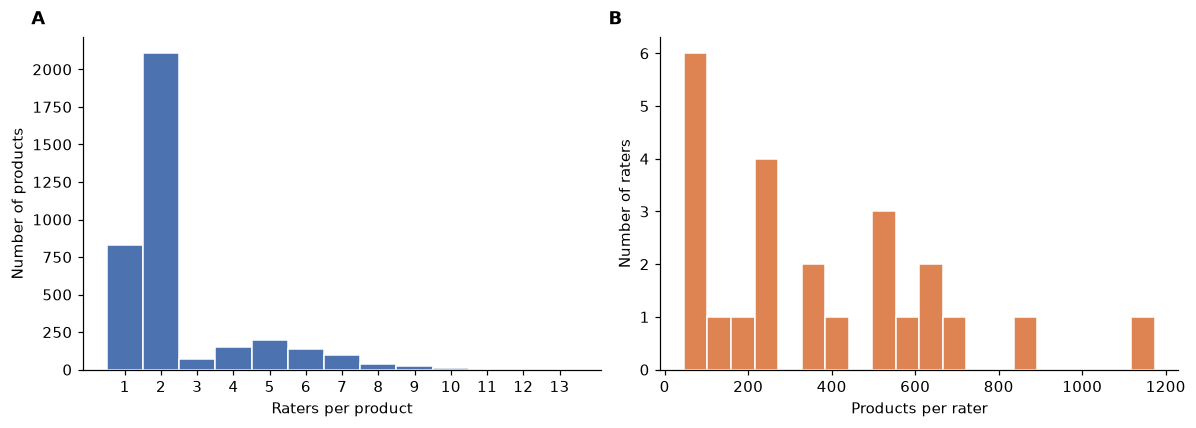

In [17]:
#| label: fig-overview-degree-distributions
#| fig-cap: "Degree distributions of the bipartite rater-product design: (A) number of raters per product, (B) number of products per rater."
fig